In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [77]:
df = sns.load_dataset("penguins")
print(df.shape)
df.head()

(344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [79]:
# rozkład etykiety
print(df["species"].value_counts(normalize=True).round(3))

# braki w procentach (tylko kolumny z brakami)
missing = df.isna().mean().mul(100).round(1)
missing[missing > 0]

species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64


,0
bill_length_mm,0.6
bill_depth_mm,0.6
flipper_length_mm,0.6
body_mass_g,0.6
sex,3.2


In [80]:
# skale i skośność cech liczbowych
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(df[num_cols].describe().round(1))
print("\nskośność:", df[num_cols].skew().round(2).to_dict())

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           342.0          342.0              342.0        342.0
mean             43.9           17.2              200.9       4201.8
std               5.5            2.0               14.1        802.0
min              32.1           13.1              172.0       2700.0
25%              39.2           15.6              190.0       3550.0
50%              44.4           17.3              197.0       4050.0
75%              48.5           18.7              213.0       4750.0
max              59.6           21.5              231.0       6300.0

skośność: {'bill_length_mm': 0.05, 'bill_depth_mm': -0.14, 'flipper_length_mm': 0.35, 'body_mass_g': 0.47}


In [81]:
print(df.groupby("species")[num_cols].mean().round(1), "\n")
print(df.pivot_table(index="island", columns="species", values="body_mass_g", aggfunc="count").fillna(0))

           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.0       3700.7
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.5           15.0              217.2       5076.0 

species    Adelie  Chinstrap  Gentoo
island                              
Biscoe       44.0        0.0   123.0
Dream        56.0       68.0     0.0
Torgersen    51.0        0.0     0.0


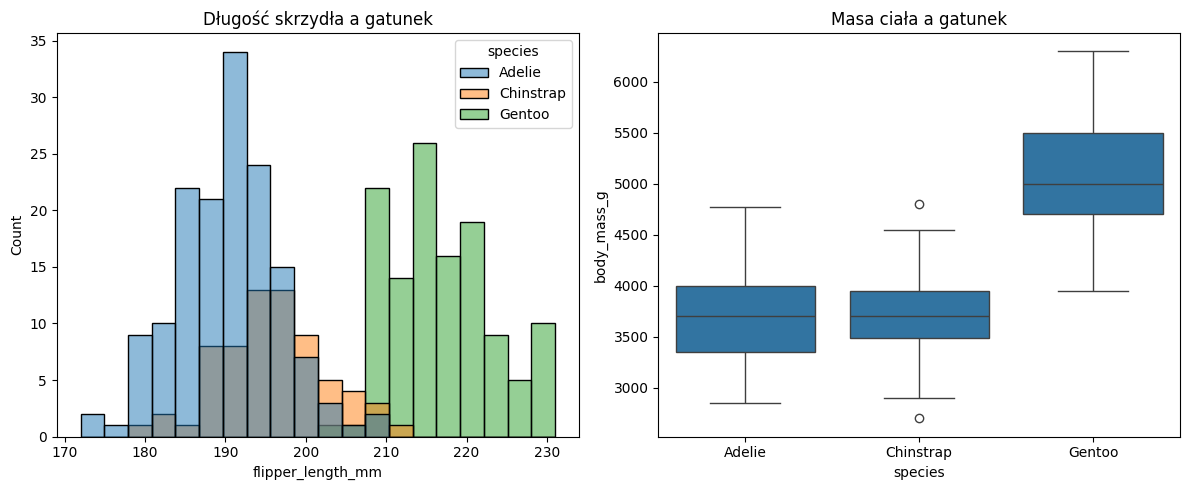

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="flipper_length_mm", hue="species", bins= 20, ax=axes[0])
axes[0].set_title("Długość skrzydła a gatunek")
sns.boxplot(data=df, x="species", y="body_mass_g", ax=axes[1])
axes[1].set_title("Masa ciała a gatunek")
fig.tight_layout()
plt.show()

In [83]:
df_c = df.dropna(subset=["species"])
print(df_c.shape)

(344, 7)


In [84]:
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g", "island", "sex"]
target = "species"

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df[target],
    test_size=0.25,
    stratify=df[target],
    random_state=42
)
print("Zbiór treningowy:", X_train.shape, "Zbiór testowy:", X_test.shape)

Zbiór treningowy: (258, 6) Zbiór testowy: (86, 6)


In [85]:
num_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cat_features = ["island", "sex"]

przygotowanie = ColumnTransformer([
    ("liczby", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_features),
    ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat_features),
])

model = make_pipeline(przygotowanie, LogisticRegression(max_iter=1000))
model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [86]:
model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('liczby',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['bill_length_mm',
                                                   'bill_depth_mm',
                                                   'flipper_length_mm',
                                                   'body_mass_g']),
                                                 ('kategorie',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['island', 'sex'])])),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [87]:
nazwy = model.named_steps["columntransformer"].get_feature_names_out()
for i, klasa in enumerate(model.named_steps["logisticregression"].classes_):
    print(f"\nCechy o największym wpływie dla klasy: {klasa}")
    wagi = pd.Series(model.named_steps["logisticregression"].coef_[i], index=nazwy).sort_values()
    display(wagi.round(3))


Cechy o największym wpływie dla klasy: Adelie


,0
liczby__bill_length_mm,-2.325
liczby__flipper_length_mm,-0.545
kategorie__island_Dream,-0.538
kategorie__sex_Female,-0.434
kategorie__island_Biscoe,-0.110
liczby__body_mass_g,0.027
kategorie__sex_Male,0.434
kategorie__island_Torgersen,0.649
liczby__bill_depth_mm,0.984



Cechy o największym wpływie dla klasy: Chinstrap


,0
liczby__body_mass_g,-0.766
kategorie__island_Biscoe,-0.740
kategorie__sex_Male,-0.480
kategorie__island_Torgersen,-0.423
liczby__flipper_length_mm,-0.302
liczby__bill_depth_mm,0.339
kategorie__sex_Female,0.481
kategorie__island_Dream,1.164
liczby__bill_length_mm,1.887



Cechy o największym wpływie dla klasy: Gentoo


,0
liczby__bill_depth_mm,-1.322
kategorie__island_Dream,-0.626
kategorie__island_Torgersen,-0.226
kategorie__sex_Female,-0.048
kategorie__sex_Male,0.046
liczby__bill_length_mm,0.438
liczby__body_mass_g,0.738
liczby__flipper_length_mm,0.847
kategorie__island_Biscoe,0.850


In [88]:
y_pred = model.predict(X_test)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

wyniki = pd.Series({
    "baseline (najczęstszy gatunek)": baseline.score(X_test, y_test),
    "pipeline – train": model.score(X_train, y_train),
    "pipeline – test": model.score(X_test, y_test),
})
display(wyniki.round(3))

,0
baseline (najczęstszy gatunek),0.442
pipeline – train,0.992
pipeline – test,1.000


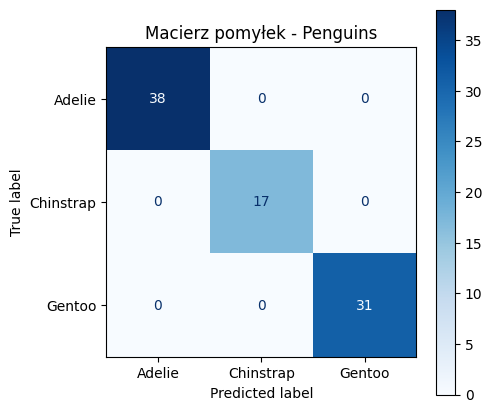

              precision    recall  f1-score   support

      Adelie      1.000     1.000     1.000        38
   Chinstrap      1.000     1.000     1.000        17
      Gentoo      1.000     1.000     1.000        31

    accuracy                          1.000        86
   macro avg      1.000     1.000     1.000        86
weighted avg      1.000     1.000     1.000        86



In [89]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap="Blues")
ax.set_title("Macierz pomyłek - Penguins")
plt.show()

print(classification_report(y_test, y_pred, digits=3))

In [90]:
def zbuduj(num, cat):
    przyg = ColumnTransformer([
        ("liczby", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        ("kategorie", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat),
    ])
    return make_pipeline(przyg, LogisticRegression(max_iter=1000))

warianty = {
    "pełny": zbuduj(num_features, cat_features),
    "bez płci": zbuduj(num_features, ["island"]),
}

pd.Series({nazwa: m.fit(X_train, y_train).score(X_test, y_test) for nazwa, m in warianty.items()}).round(3)

,0
pełny,1.0
bez płci,1.0
